# Nucleation Rate

This example will compute the nucleation rate with various precipitate parameters.

Note: the `computeSteadyStateNucleation` function does not account for the number of nucleation sites

### Comparing multiple phases in Al-Mg-Si system

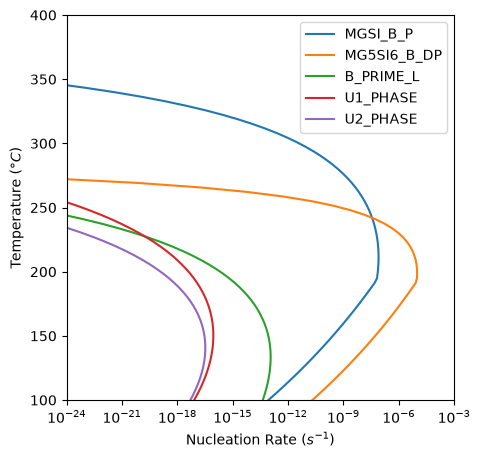

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pycalphad import variables as v

from kawin.thermo.thermodynamics import Thermodynamics
from kawin.precipitation.nucleation_rate import compute_steady_state_nucleation
from kawin.precipitation.parameters.volume import Volume
from kawin.precipitation.precipitation_parameters import MatrixParameters, PrecipitateParameters

matrix_phase = ['FCC_A1']
precipitate_phases = ['MGSI_B_P', 'MG5SI6_B_DP', 'B_PRIME_L', 'U1_PHASE', 'U2_PHASE']
therm = Thermodynamics('AlMgSi.tdb', ['AL', 'MG', 'SI', 'VA'], matrix_phase, precipitate_phases)

matrix = MatrixParameters('FCC_A1', {}, Volume.from_vm(1e-5, 4))

gamma = {
    'MGSI_B_P': 0.18,
    'MG5SI6_B_DP': 0.084,
    'B_PRIME_L': 0.18,
    'U1_PHASE': 0.18,
    'U2_PHASE': 0.18
}

precipitates = []
for p in precipitate_phases:
    params = PrecipitateParameters(p, gamma[p], Volume.from_vm(1e-5, 4))
    precipitates.append(params)

fig, ax = plt.subplots(figsize=(5,5))
T = np.linspace(50, 400, 100) + 273.15
for prec in precipitates:
    nuc_rate = compute_steady_state_nucleation(
        therm, {v.X('MG'): 0.0072, v.X('SI'): 0.0057, v.T: T}, matrix, prec
        )
    #nucRate = computeSteadyStateNucleation(therm, [0.0072, 0.0057], T, prec, matrix)
    ax.plot(nuc_rate.nucleation_rate, T-273.15, label=prec.phase)
ax.set_ylim([100, 400])
ax.set_xlim([1e-24, 1e-3])
ax.set_xscale('log')
ax.set_xlabel(r'Nucleation Rate ($s^{-1}$)')
ax.set_ylabel(r'Temperature ($\degree C $)')
ax.legend()
plt.show()

### Comparing nucleation on different nucleation sites for Al-Zr

C:\Users\ury3\Documents\codes\kawin_redesign\kawin\kawin\precipitation\nucleation_rate.py:138: RuntimeWarning: divide by zero encountered in scalar divide
  beta = prec.nucleation_site.area_factor(prec.gamma, mat.gb_energy)*r_crit**2*(1/D_factor) / mat.volume.a**4


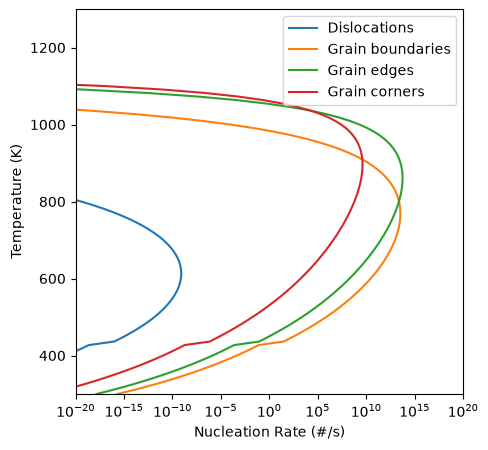

In [2]:
from kawin.thermo.thermodynamics import set_manual_diffusivity
from kawin.precipitation.parameters.nucleation import DislocationDescription, GrainBoundaryDescription, GrainEdgeDescription, GrainCornerDescription
from kawin.precipitation.parameters.nucleation import NucleationSites

therm = Thermodynamics('AlScZr.tdb', ['AL', 'ZR', 'VA'], ['FCC_A1'], ['AL3ZR'])

D0 = 0.0768         #Diffusivity pre-factor (m2/s)
Q = 242000          #Activation energy (J/mol)
diff = lambda T: D0 * np.exp(-Q / (8.314 * T))
set_manual_diffusivity(therm, diff, 'FCC_A1')

a = 0.405e-9      # nm
Va = a**3         # nm^3
atomsPerCell = 4

mat = MatrixParameters('FCC_A1', ['ZR'], Volume.from_vm(1e-5, 4))
mat.gb_energy = 0.3
mat.dislocation_density = 1e15
mat.grain_size = 100e-6

prec = PrecipitateParameters('AL3ZR', 0.25, Volume.from_vm(1e-5, 4))

nucleation_sites = {
    'dislocations': DislocationDescription(),
    'grain boundaries': GrainBoundaryDescription(),
    'grain edges': GrainEdgeDescription(),
    'grain corners': GrainCornerDescription(),
}
N0 = {
    'dislocations': NucleationSites.dislocation_n0(mat.dislocation_density, mat.volume.vm),
    'grain boundaries': NucleationSites.gb_area_n0(mat.grain_size, mat.grain_aspect_ratio, mat.volume.vm),
    'grain edges': NucleationSites.gb_edge_n0(mat.grain_size, mat.grain_aspect_ratio, mat.volume.vm),
    'grain corners': NucleationSites.gb_corner_n0(mat.grain_size, mat.grain_aspect_ratio, mat.volume.vm),
}

fig, ax = plt.subplots(figsize=(5,5))
T = np.linspace(300, 1200, 100)
for site in nucleation_sites:
    prec.nucleation_site = nucleation_sites[site]
    nuc_rate = compute_steady_state_nucleation(therm, {v.X('ZR'): 4e-3, v.T: T}, mat, prec)
    ax.plot(N0[site]*nuc_rate.nucleation_rate, T, label=site.capitalize())
ax.legend()
ax.set_xlim([1e-20, 1e20])
ax.set_xscale('log')
ax.set_ylim([300, 1300])
ax.set_xlabel('Nucleation Rate (#/s)')
ax.set_ylabel('Temperature (K)')
plt.show()